# Rodada 8 — paciência em todos os algoritmos, Optuna e transformações

Segue a orientação do professor, na ordem que ele pediu:

1. **Critério de parada por paciência em todos os algoritmos.** Nenhum modelo
   treina mais com número fixo de épocas/árvores. Redes (MLP, STab, TabKAN, KAN)
   param após **30 épocas** sem melhora do AUROC de validação; boosting
   (GB, XGBoost, CatBoost) após **200 árvores** sem melhora. O teto
   (3000 épocas / 20000 árvores) é só trava de segurança e fica registrado
   (`teto_atingido`). Antes: o GB usava 100–209 árvores fixas, e STab/TabKAN/KAN
   tinham tetos de 100–200 épocas com paciência 8–15.
2. **Baseline (etapa A):** todas as variáveis, todos os algoritmos, hiperparâmetros
   padrão, só com a paciência.
3. **Optuna (etapa B):** busca na partição 0 (AUROC de validação), **sem nº de
   épocas/árvores no espaço** — a paciência decide. O padrão entra como 1º trial.
   Depois, avaliação nas 5 partições.
4. **Transformações das variáveis (etapa C)**, só depois do baseline: faixas por
   quantil (do treino) de `tenure`/`MonthlyCharges`/`TotalCharges`, acrescentadas
   ou substituindo a contínua, e `log1p(TotalCharges)` (cauda longa) nas redes.
5. **Treino final em treino+validação (etapa D):** XGB, GB e TabPFN re-treinados
   com 75% dos dados, número de árvores fixado pela paciência da etapa B (+25%).
   Única alavanca que traz *informação nova* ao modelo (+50% de linhas).
6. **Ensembles (etapa E):** média dos logits do melhor de cada algoritmo, com os
   membros escolhidos **só pela validação**.

Protocolo igual para todos nesta rodada: paciência olhando a validação **sem as
cópias** do oversampling; `Preprocessor` ajustado no treino sem cópias; teste
sempre na distribuição real. Cada (configuração, partição) é salva em
`results/avaliacao_5_particoes/rodada8/` assim que termina.

**Retomada:** se a sessão do Kaggle esgotar (12 h), o notebook para de começar
treinos novos após `ORCAMENTO_HORAS`, salva e envia o que tem para a branch
`results/churn-rodada8-paciencia`. Rode de novo: o setup traz esses resultados
de volta e só o que falta é treinado.

Checklist: *Settings → Internet On*, *Accelerator → GPU*, segredo `GITHUB_TOKEN`;
"Save Version → Save & Run All".

In [1]:
#@title Setup (clona o repo, instala o pacote e recupera resultados parciais desta rodada)
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/jpbezerra/redes-neurais.git"
BRANCH   = "feat/churn"
RESULTS_BRANCH = "results/churn-rodada8-paciencia"   # onde esta rodada grava (e de onde retoma)
REPO_DIR = "redes-neurais"
SUBPATH  = "projeto/churn-telecom"

def _sh(cmd):
    print("$", cmd); return subprocess.run(cmd, shell=True, check=False).returncode

IN_KAGGLE = os.path.exists("/kaggle")
if IN_KAGGLE:
    root = Path("/kaggle/temp") / REPO_DIR   # fora de /kaggle/working: o clone nao entra no Output
    if root.exists():
        _sh(f"cd {root} && git fetch origin {BRANCH} && git checkout {BRANCH} && git pull --ff-only origin {BRANCH}")
    else:
        _sh(f"git clone --branch {BRANCH} --single-branch {REPO_URL} {root}")
    PROJECT_ROOT = root / SUBPATH
    _sh(f"pip install -q -e {PROJECT_ROOT}")
    # Retomada: se uma execucao anterior ja enviou parte desta rodada, traz esses
    # resultados para o clone — as etapas ja feitas sao puladas.
    if _sh(f"git -C {root} fetch origin {RESULTS_BRANCH}") == 0:
        for p in (f"{SUBPATH}/results/avaliacao_5_particoes/rodada8", f"{SUBPATH}/reports/tables"):
            _sh(f"git -C {root} checkout FETCH_HEAD -- {p}")
else:
    PROJECT_ROOT = Path.cwd().parent
    root = PROJECT_ROOT.parents[1]

SRC = PROJECT_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

OUT_DIR = Path("/kaggle/working/saida") if IN_KAGGLE else PROJECT_ROOT
RESULTS_DIR  = OUT_DIR / "results"
TABLES_DIR   = OUT_DIR / "reports" / "tables"
FIGURES_DIR  = OUT_DIR / "reports" / "figures"
RESULTS_REPO = PROJECT_ROOT / "results"
TABLES_REPO  = PROJECT_ROOT / "reports" / "tables"
for d in (RESULTS_DIR, TABLES_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("PROJECT_ROOT:", PROJECT_ROOT)

$ git clone --branch feat/churn --single-branch https://github.com/jpbezerra/redes-neurais.git /kaggle/temp/redes-neurais


Cloning into '/kaggle/temp/redes-neurais'...
Updating files: 100% (1871/1871), done.


$ pip install -q -e /kaggle/temp/redes-neurais/projeto/churn-telecom
$ git -C /kaggle/temp/redes-neurais fetch origin results/churn-rodada8-paciencia
PROJECT_ROOT: /kaggle/temp/redes-neurais/projeto/churn-telecom


fatal: couldn't find remote ref results/churn-rodada8-paciencia


In [2]:
!pip install -q tabpfn pykan tabkan catboost optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 850.0/850.0 kB 23.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.0/82.0 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 595.9/595.9 kB 27.7 MB/s eta 0:00:00


## Configuração e partições

In [3]:
import json, time, traceback
import numpy as np
import pandas as pd
import torch

from churn_telecom.data import load_raw
from churn_telecom import rodada8 as r8
from churn_telecom.ensemble import media_logits

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

SEEDS = range(5)
ORCAMENTO_HORAS = 11.0   # Kaggle derruba a sessao em 12 h: depois disso nada novo comeca, e o notebook salva o que tem
PRAZO = time.time() + ORCAMENTO_HORAS * 3600
# Etapas (desligue para dividir a rodada em mais de uma execucao — a retomada e automatica)
ETAPAS = {"A_baseline": True, "B_optuna": True, "C_transformacoes": True, "D_treino_mais_validacao": True,
          "E_ensembles": True}

df = load_raw(PROJECT_ROOT / "data")
PARTICOES = {s: r8.preparar_particao(df, s) for s in SEEDS}
BASES = [RESULTS_DIR, RESULTS_REPO]   # grava na 1a; le das duas (retomada)
FALHAS = {}

class TempoEsgotado(Exception):
    pass

def rodar_config(nome, alg, hp, etapa, **kw):
    """Uma configuracao nas 5 particoes (pula as ja feitas)."""
    for s, part in PARTICOES.items():
        if time.time() > PRAZO:
            raise TempoEsgotado(nome)
        try:
            m = r8.treinar_e_avaliar(nome, alg, hp, part, results_dirs=BASES, device=device,
                                     extra={"etapa": etapa}, **kw)
            pac = m["dataset"]["paciencia"]
            print(f"[{etapa}] {nome:45s} p{s} ks={m['metrics']['ks']:.4f} auroc={m['metrics']['auroc']:.4f} "
                  f"iter={pac.get('melhor_epoca', pac.get('melhor_iteracao', '-'))} teto={pac.get('teto_atingido', '-')}",
                  flush=True)
        except TempoEsgotado:
            raise
        except Exception as e:
            FALHAS[f"{nome}_p{s}"] = f"{type(e).__name__}: {e}"
            print(f"[FALHOU] {nome} p{s}: {type(e).__name__}: {e}")
            traceback.print_exc()

def etapa(nome, fn):
    if not ETAPAS.get(nome):
        print(f"[desligada] {nome}"); return
    try:
        fn()
    except TempoEsgotado as e:
        print(f"[tempo esgotado] {nome} parou em {e}; rode de novo para continuar (retomada automatica)")

device: cuda
Baixando CSV de https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv ...
CSV salvo em /kaggle/temp/redes-neurais/projeto/churn-telecom/data/telco_customer_churn.csv


## Etapa A — baseline com paciência (todas as variáveis, todos os algoritmos)

In [4]:
def etapa_A():
    for a in r8.ALGORITMOS.values():
        rodar_config(f"{a.nome}_padrao_paciencia", a, a.padrao, "A_baseline")

etapa("A_baseline", etapa_A)

[A_baseline] mlp_padrao_paciencia                          p0 ks=0.5079 auroc=0.8290 iter=8 teto=False
[A_baseline] mlp_padrao_paciencia                          p1 ks=0.5252 auroc=0.8400 iter=11 teto=False
[A_baseline] mlp_padrao_paciencia                          p2 ks=0.5240 auroc=0.8379 iter=23 teto=False
[A_baseline] mlp_padrao_paciencia                          p3 ks=0.5357 auroc=0.8465 iter=10 teto=False
[A_baseline] mlp_padrao_paciencia                          p4 ks=0.5305 auroc=0.8460 iter=5 teto=False
[A_baseline] gb_padrao_paciencia                           p0 ks=0.5108 auroc=0.8333 iter=42 teto=False
[A_baseline] gb_padrao_paciencia                           p1 ks=0.5209 auroc=0.8399 iter=64 teto=False
[A_baseline] gb_padrao_paciencia                           p2 ks=0.5429 auroc=0.8441 iter=93 teto=False
[A_baseline] gb_padrao_paciencia                           p3 ks=0.5373 auroc=0.8468 iter=85 teto=False
[A_baseline] gb_padrao_paciencia                           p4 ks=0

tabpfn-v2-classifier-finetuned-zk73skhh.(…): reconstructing file:   0%|          |  0.00B / 29.0MB            

tabpfn-v2-classifier-finetuned-zk73skhh.(…): downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/37.0 [00:00<?, ?B/s]

[A_baseline] tabpfn_padrao_paciencia                       p0 ks=0.5161 auroc=0.8401 iter=- teto=-
[A_baseline] tabpfn_padrao_paciencia                       p1 ks=0.5427 auroc=0.8453 iter=- teto=-
[A_baseline] tabpfn_padrao_paciencia                       p2 ks=0.5539 auroc=0.8514 iter=- teto=-
[A_baseline] tabpfn_padrao_paciencia                       p3 ks=0.5413 auroc=0.8529 iter=- teto=-
[A_baseline] tabpfn_padrao_paciencia                       p4 ks=0.5245 auroc=0.8443 iter=- teto=-


## Etapa B — Optuna com paciência (partição 0) e avaliação em 5 partições

In [5]:
def melhores_hp(a):
    """Le o melhor trial salvo (retomada) ou roda a busca na particao 0."""
    nome_json = f"rodada8_optuna_{a.nome}_melhor.json"
    for base in (TABLES_DIR, TABLES_REPO):
        if (base / nome_json).exists():
            return json.loads((base / nome_json).read_text())["params"]
    if time.time() > PRAZO:
        raise TempoEsgotado(f"optuna_{a.nome}")
    t0 = time.time()
    params, trials, imp = r8.otimizar(a, PARTICOES[0], device, timeout=PRAZO - time.time())
    trials.to_csv(TABLES_DIR / f"rodada8_optuna_{a.nome}_trials.csv", index=False)
    (TABLES_DIR / nome_json).write_text(json.dumps(
        {"params": params, "auroc_validacao": float(trials["value"].max()), "n_trials": len(trials),
         "importancias": imp, "minutos": round((time.time() - t0) / 60, 1)}, indent=2))
    print(f"optuna {a.nome}: {len(trials)} trials, melhor AUROC val={trials['value'].max():.4f} -> {params}")
    return params

def etapa_B():
    for a in r8.ALGORITMOS.values():
        if a.espaco is None:
            continue   # TabPFN: sem hiperparametros de treino
        try:
            hp = melhores_hp(a)
        except TempoEsgotado:
            raise
        except Exception as e:
            FALHAS[f"optuna_{a.nome}"] = f"{type(e).__name__}: {e}"; traceback.print_exc(); continue
        rodar_config(f"{a.nome}_optuna_paciencia", a, hp, "B_optuna")

etapa("B_optuna", etapa_B)

optuna mlp: 40 trials, melhor AUROC val=0.8471 -> {'n_camadas': 1, 'largura': 208, 'activation': 'tanh', 'alpha': 1.3636820339565106e-05, 'learning_rate_init': 0.0001435889151710775, 'batch_size': 128}
[B_optuna] mlp_optuna_paciencia                          p0 ks=0.5015 auroc=0.8322 iter=98 teto=False
[B_optuna] mlp_optuna_paciencia                          p1 ks=0.5253 auroc=0.8434 iter=104 teto=False
[B_optuna] mlp_optuna_paciencia                          p2 ks=0.5409 auroc=0.8447 iter=71 teto=False
[B_optuna] mlp_optuna_paciencia                          p3 ks=0.5300 auroc=0.8478 iter=83 teto=False
[B_optuna] mlp_optuna_paciencia                          p4 ks=0.5375 auroc=0.8455 iter=86 teto=False
optuna gb: 50 trials, melhor AUROC val=0.8531 -> {'learning_rate': 0.081609472566639, 'max_depth': 3, 'min_samples_leaf': 11, 'subsample': 0.6431564745543757}
[B_optuna] gb_optuna_paciencia                           p0 ks=0.5192 auroc=0.8337 iter=57 teto=False
[B_optuna] gb_optuna_pacie

## Etapa C — transformações das variáveis contínuas

In [6]:
def hp_final(a):
    p = TABLES_DIR / f"rodada8_optuna_{a.nome}_melhor.json"
    p = p if p.exists() else TABLES_REPO / p.name
    return (json.loads(p.read_text())["params"], "optuna") if p.exists() else (a.padrao, "padrao")

def etapa_C():
    for t in ("faixas_adiciona", "faixas_substitui", "log"):
        for a in r8.ALGORITMOS.values():
            if t == "log" and a.modo == "arvores":
                continue   # log e monotonica: arvores dao exatamente o mesmo resultado
            hp, origem = hp_final(a)
            rodar_config(f"{a.nome}_{origem}_paciencia_{t}", a, hp, "C_transformacoes", transformacao=t)

etapa("C_transformacoes", etapa_C)

[C_transformacoes] mlp_optuna_paciencia_faixas_adiciona          p0 ks=0.5177 auroc=0.8400 iter=11 teto=False
[C_transformacoes] mlp_optuna_paciencia_faixas_adiciona          p1 ks=0.5431 auroc=0.8437 iter=15 teto=False
[C_transformacoes] mlp_optuna_paciencia_faixas_adiciona          p2 ks=0.5440 auroc=0.8499 iter=125 teto=False
[C_transformacoes] mlp_optuna_paciencia_faixas_adiciona          p3 ks=0.5462 auroc=0.8519 iter=9 teto=False
[C_transformacoes] mlp_optuna_paciencia_faixas_adiciona          p4 ks=0.5353 auroc=0.8487 iter=6 teto=False
[C_transformacoes] gb_optuna_paciencia_faixas_adiciona           p0 ks=0.5192 auroc=0.8337 iter=57 teto=False
[C_transformacoes] gb_optuna_paciencia_faixas_adiciona           p1 ks=0.5298 auroc=0.8384 iter=118 teto=False
[C_transformacoes] gb_optuna_paciencia_faixas_adiciona           p2 ks=0.5475 auroc=0.8454 iter=50 teto=False
[C_transformacoes] gb_optuna_paciencia_faixas_adiciona           p3 ks=0.5402 auroc=0.8500 iter=71 teto=False
[C_transfo

## Etapa D — treino final em treino + validação

In [7]:
FATOR_ITER = 1.25   # ponytail: +25% de iteracoes para +50% de linhas, heuristica comum; sem validacao para conferir

def etapa_D():
    for nome_alg in ("xgb", "gb", "tabpfn"):
        a = r8.ALGORITMOS.get(nome_alg)
        if a is None:
            continue
        hp, origem = hp_final(a)
        for s, part in PARTICOES.items():
            if time.time() > PRAZO:
                raise TempoEsgotado(nome_alg)
            n = None
            if a.nome != "tabpfn":   # numero de arvores = o que a paciencia escolheu nesta particao (etapa B/A)
                ref = f"{a.nome}_{origem}_paciencia"
                meta = next((r8.pasta_de(b, ref, s) / "metadata.json" for b in BASES
                             if (r8.pasta_de(b, ref, s) / "metadata.json").exists()), None)
                if meta is None:
                    print(f"[pulado] {ref} p{s} ainda nao existe"); continue
                n = int(round(json.loads(meta.read_text())["dataset"]["paciencia"]["melhor_iteracao"] * FATOR_ITER))
            nome = f"{a.nome}_{origem}_treino_mais_validacao"
            try:
                m = r8.treinar_e_avaliar(nome, a, hp, part, results_dirs=BASES, device=device,
                                         treino_final_trval=True, n_iter_fixo=n,
                                         extra={"etapa": "D_treino_mais_validacao"})
                print(f"[D] {nome:45s} p{s} ks={m['metrics']['ks']:.4f} n_iter={n}")
            except Exception as e:
                FALHAS[f"{nome}_p{s}"] = f"{type(e).__name__}: {e}"; traceback.print_exc()

etapa("D_treino_mais_validacao", etapa_D)

[D] xgb_optuna_treino_mais_validacao              p0 ks=0.5135 n_iter=94
[D] xgb_optuna_treino_mais_validacao              p1 ks=0.5329 n_iter=141
[D] xgb_optuna_treino_mais_validacao              p2 ks=0.5619 n_iter=162
[D] xgb_optuna_treino_mais_validacao              p3 ks=0.5508 n_iter=114
[D] xgb_optuna_treino_mais_validacao              p4 ks=0.5303 n_iter=68
[D] gb_optuna_treino_mais_validacao               p0 ks=0.5217 n_iter=71
[D] gb_optuna_treino_mais_validacao               p1 ks=0.5161 n_iter=148
[D] gb_optuna_treino_mais_validacao               p2 ks=0.5599 n_iter=62
[D] gb_optuna_treino_mais_validacao               p3 ks=0.5410 n_iter=89
[D] gb_optuna_treino_mais_validacao               p4 ks=0.5244 n_iter=55
[D] tabpfn_padrao_treino_mais_validacao           p0 ks=0.5095 n_iter=None
[D] tabpfn_padrao_treino_mais_validacao           p1 ks=0.5423 n_iter=None
[D] tabpfn_padrao_treino_mais_validacao           p2 ks=0.5585 n_iter=None
[D] tabpfn_padrao_treino_mais_validacao  

## Etapa E — ensembles (membros escolhidos pela validação)

In [8]:
def etapa_E():
    longo = r8.carregar(BASES)
    cand = longo[longo.etapa.isin(["A_baseline", "B_optuna", "C_transformacoes"])]
    # escolha SO pela validacao: AUROC medio de validacao nas 5 particoes
    val = cand.groupby(["familia", "modelo"]).agg(n=("seed", "size"), auroc_val=("auroc_validacao", "mean")).reset_index()
    val = val[val.n == len(SEEDS)]
    melhor_fam = val.loc[val.groupby("familia")["auroc_val"].idxmax()].sort_values("auroc_val", ascending=False)
    print(melhor_fam.to_string(index=False))
    grupos = {"ensemble_melhor_de_cada_algoritmo": list(melhor_fam.modelo),
              "ensemble_top3_validacao": list(melhor_fam.modelo[:3])}
    for nome, membros in grupos.items():
        for s, part in PARTICOES.items():
            if any((r8.pasta_de(b, nome, s) / "metadata.json").exists() for b in BASES):
                continue
            pastas = [Path(longo[(longo.modelo == m) & (longo.seed == s)].pasta.iloc[0]) for m in membros]
            pr = [np.load(p / "predicoes.npz") for p in pastas]
            pv, pt = media_logits([x["p_val"] for x in pr]), media_logits([x["p_test"] for x in pr])
            m = r8.registrar(nome, part, pv, pt, RESULTS_DIR, hp={"combinacao": "media dos logits", "membros": membros},
                             dataset={"algoritmo": "ensemble", "familia": "Ensemble", "codificacao": "-",
                                      "transformacao": "-", "treino": "-", "n_linhas_treino": 0},
                             paciencia={}, extra={"etapa": "E_ensembles"})
            print(f"[E] {nome} p{s} ks={m['metrics']['ks']:.4f}")

etapa("E_ensembles", etapa_E)

          familia                                    modelo  n  auroc_val
        TabPFN v2               tabpfn_padrao_paciencia_log  5   0.847957
             STab                 stab_optuna_paciencia_log  5   0.847744
          XGBoost      xgb_optuna_paciencia_faixas_adiciona  5   0.846816
         CatBoost catboost_optuna_paciencia_faixas_adiciona  5   0.846557
           TabKAN               tabkan_optuna_paciencia_log  5   0.846360
              MLP                  mlp_optuna_paciencia_log  5   0.846132
              KAN                  kan_optuna_paciencia_log  5   0.845893
Gradient Boosting       gb_optuna_paciencia_faixas_adiciona  5   0.845374
[E] ensemble_melhor_de_cada_algoritmo p0 ks=0.5100
[E] ensemble_melhor_de_cada_algoritmo p1 ks=0.5407
[E] ensemble_melhor_de_cada_algoritmo p2 ks=0.5548
[E] ensemble_melhor_de_cada_algoritmo p3 ks=0.5459
[E] ensemble_melhor_de_cada_algoritmo p4 ks=0.5304
[E] ensemble_top3_validacao p0 ks=0.5092
[E] ensemble_top3_validacao p1 ks=0.54

## Resumo

In [9]:
longo = r8.carregar(BASES)
resumo = r8.resumir(longo)
longo.drop(columns="pasta").to_csv(TABLES_DIR / "rodada8_metricas_por_particao.csv", index=False)
resumo.to_csv(TABLES_DIR / "rodada8_resumo.csv", index=False)
pd.DataFrame([{"etapa": k, "erro": v} for k, v in FALHAS.items()], columns=["etapa", "erro"]).to_csv(
    TABLES_DIR / "rodada8_falhas.csv", index=False)
print("Falhas:", FALHAS or "nenhuma")
resumo.head(30)

Falhas: nenhuma


,modelo,algoritmo,familia,etapa,n_particoes,ks_mean,ks_std,auroc_mean,acuracia_limiar_validacao_mean,auroc_validacao_mean,iteracoes_mediana,teto_atingido
19,mlp_optuna_paciencia_log,mlp,MLP,C_transformacoes,5,0.540938,0.014819,0.845666,0.801817,0.846132,15.0,0
37,xgb_optuna_paciencia_faixas_adiciona,xgb,XGBoost,C_transformacoes,5,0.539719,0.015902,0.846091,0.802271,0.846816,86.0,0
5,ensemble_top3_validacao,ensemble,Ensemble,E_ensembles,5,0.537914,0.018990,0.847512,0.803975,0.849100,NaN,0
39,xgb_optuna_treino_mais_validacao,xgb,XGBoost,D_treino_mais_validacao,5,0.537874,0.018845,0.846669,0.802158,0.861885,114.0,0
18,mlp_optuna_paciencia_faixas_substitui,mlp,MLP,C_transformacoes,5,0.537381,0.014957,0.843851,0.797274,0.843956,16.0,0
17,mlp_optuna_paciencia_faixas_adiciona,mlp,MLP,C_transformacoes,5,0.537258,0.011693,0.846826,0.801363,0.845306,11.0,0
35,tabpfn_padrao_treino_mais_validacao,tabpfn,TabPFN v2,D_treino_mais_validacao,5,0.536952,0.018732,0.848247,0.804884,0.865014,NaN,0
36,xgb_optuna_paciencia,xgb,XGBoost,B_optuna,5,0.536777,0.018325,0.845553,0.801817,0.846255,91.0,0
32,tabpfn_padrao_paciencia_faixas_adiciona,tabpfn,TabPFN v2,C_transformacoes,5,0.536620,0.017627,0.846546,0.803634,0.847025,NaN,0
4,ensemble_melhor_de_cada_algoritmo,ensemble,Ensemble,E_ensembles,5,0.536343,0.017150,0.847269,0.803975,0.848724,NaN,0


### Testes pareados

`veredito = ruido` quando o IC 95% cruza zero.

In [10]:
# Comparacoes pareadas (mesma particao): efeito de cada passo, IC 95% (t, 4 g.l.)
comp = []
for a in r8.ALGORITMOS.values():
    _, origem = hp_final(a)
    base = f"{a.nome}_{origem}_paciencia"
    if origem == "optuna":
        comp.append(r8.comparar_pareado(longo, base, f"{a.nome}_padrao_paciencia"))
    for t in ("faixas_adiciona", "faixas_substitui", "log"):
        comp.append(r8.comparar_pareado(longo, f"{base}_{t}", base))
    comp.append(r8.comparar_pareado(longo, f"{a.nome}_{origem}_treino_mais_validacao", base))
# referencia do ensemble: melhor individual PELA VALIDACAO (etapa D fica fora: la a validacao esta no treino)
indiv = resumo[resumo.etapa.isin(["A_baseline", "B_optuna", "C_transformacoes"]) & (resumo.n_particoes == 5)]
melhor_individual = indiv.sort_values("auroc_validacao_mean").modelo.iloc[-1]
for e in ("ensemble_melhor_de_cada_algoritmo", "ensemble_top3_validacao"):
    comp.append(r8.comparar_pareado(longo, e, melhor_individual))
comp = pd.DataFrame([c for c in comp if c.get("n", 0) >= 2])
comp.to_csv(TABLES_DIR / "rodada8_comparacoes_pareadas.csv", index=False)
comp

,novo,referencia,n,delta_ks,ic95_inf,ic95_sup,veredito
0,mlp_optuna_paciencia,mlp_padrao_paciencia,5,0.002397,-0.009680,0.014473,ruido
1,mlp_optuna_paciencia_faixas_adiciona,mlp_optuna_paciencia,5,0.010196,-0.001203,0.021595,ruido
2,mlp_optuna_paciencia_faixas_substitui,mlp_optuna_paciencia,5,0.010319,-0.002848,0.023485,ruido
3,mlp_optuna_paciencia_log,mlp_optuna_paciencia,5,0.013876,0.008958,0.018795,melhor
4,gb_optuna_paciencia,gb_padrao_paciencia,5,0.005196,0.001042,0.009350,melhor
5,gb_optuna_paciencia_faixas_adiciona,gb_optuna_paciencia,5,0.000000,0.000000,0.000000,ruido
6,gb_optuna_paciencia_faixas_substitui,gb_optuna_paciencia,5,-0.004954,-0.021233,0.011326,ruido
7,gb_optuna_treino_mais_validacao,gb_optuna_paciencia,5,0.001351,-0.010505,0.013208,ruido
8,xgb_optuna_paciencia,xgb_padrao_paciencia,5,0.006816,-0.006387,0.020019,ruido
9,xgb_optuna_paciencia_faixas_adiciona,xgb_optuna_paciencia,5,0.002942,-0.004800,0.010683,ruido


### Curvas de paciência

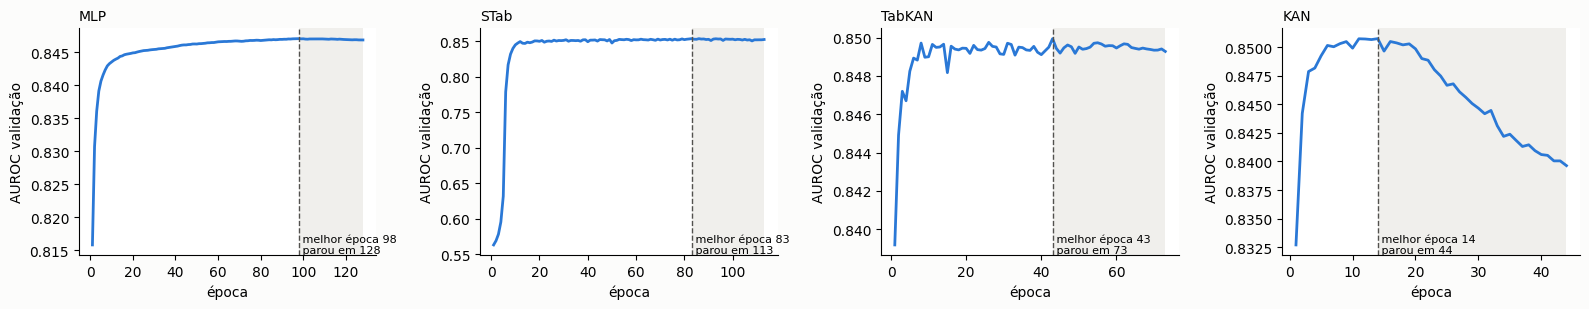

In [11]:
# Curvas de validacao com o ponto escolhido pela paciencia (particao 0, config Optuna)
import matplotlib.pyplot as plt
redes = [a for a in r8.ALGORITMOS.values() if a.modo == "neural" and a.nome != "tabpfn"]
fig, axes = plt.subplots(1, len(redes), figsize=(4 * len(redes), 3.2), facecolor="#fcfcfb")
for ax, a in zip(np.atleast_1d(axes), redes):
    _, origem = hp_final(a)
    h = next((r8.pasta_de(b, f"{a.nome}_{origem}_paciencia", 0) / "history.csv" for b in BASES
              if (r8.pasta_de(b, f"{a.nome}_{origem}_paciencia", 0) / "history.csv").exists()), None)
    ax.set_title(a.familia, loc="left", fontsize=10)
    if h is None:
        continue
    h = pd.read_csv(h)
    ax.plot(np.arange(1, len(h) + 1), h["val_auroc"], color="#2a78d6", lw=2)
    melhor = int(h["val_auroc"].idxmax()) + 1
    ax.axvline(melhor, color="#52514e", ls="--", lw=1)
    ax.axvspan(melhor, len(h), color="#e6e5e0", alpha=0.6, lw=0)
    ax.text(melhor, ax.get_ylim()[0], f" melhor época {melhor}\n parou em {len(h)}", fontsize=8, va="bottom")
    ax.set_xlabel("época"); ax.set_ylabel("AUROC validação")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "rodada8_curvas_paciencia.png", dpi=150)

## Salvando (zip no Output + push para `results/churn-rodada8-paciencia`)

In [12]:
import shutil
LIMITE_MB = 20

def salvar_saida():
    if not IN_KAGGLE:
        return
    print("Zip:", shutil.make_archive("/kaggle/working/results_rodada8", "zip", OUT_DIR))
    try:
        from kaggle_secrets import UserSecretsClient
        token = UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception:
        token = None
    if not token:
        print("Sem segredo GITHUB_TOKEN: baixe o zip pelo Output."); return
    try:
        pulados = []
        for origem, destino in ((RESULTS_DIR, RESULTS_REPO), (TABLES_DIR, TABLES_REPO),
                                (FIGURES_DIR, PROJECT_ROOT / "reports" / "figures")):
            for f in Path(origem).rglob("*"):
                if not f.is_file():
                    continue
                if f.stat().st_size > LIMITE_MB * 1024 * 1024:
                    pulados.append(str(f)); continue
                alvo = Path(destino) / f.relative_to(origem)
                # tabelas/figuras desta rodada podem ser atualizadas na retomada; resultados nunca
                if alvo.exists() and not alvo.name.startswith("rodada8_"):
                    continue
                alvo.parent.mkdir(parents=True, exist_ok=True)
                shutil.copy2(f, alvo)
        if pulados:
            print("Arquivos grandes so no zip:", pulados)

        def git(*args):
            r = subprocess.run(["git", "-C", str(root), "-c", "user.name=kaggle-run",
                                "-c", "user.email=kaggle-run@users.noreply.github.com", *args],
                               capture_output=True, text=True)
            saida = (r.stdout + r.stderr).replace(token, "***")
            if r.returncode != 0 and "nothing to commit" not in saida:
                raise RuntimeError(f"git {args[0]} falhou: {saida}")
            return saida

        git("checkout", "-B", RESULTS_BRANCH)
        git("add", "-f", f"{SUBPATH}/results", f"{SUBPATH}/reports/tables", f"{SUBPATH}/reports/figures")
        git("commit", "-m", "results: rodada 8 (paciencia, Optuna, transformacoes) — Kaggle")
        git("push", "--force", REPO_URL.replace("https://", f"https://x-access-token:{token}@"),
            f"HEAD:refs/heads/{RESULTS_BRANCH}")
        print(f"Enviado para a branch {RESULTS_BRANCH}.")
    except Exception as e:
        print("Push falhou (o zip continua valido):", str(e)[:600])

salvar_saida()

Zip: /kaggle/working/results_rodada8.zip
Push falhou (o zip continua valido): git push falhou: remote: Invalid username or token. Password authentication is not supported for Git operations.
fatal: Authentication failed for 'https://github.com/jpbezerra/redes-neurais.git/'

